**Table of contents**<a id='toc0_'></a>

- [1 - Introdução](#toc2_)
- [2 - Modelo Matemático](#toc3_)
    - [2.1 Estrutura da Malha Fechada](#toc3_0_1_)
    - [2.2 Variáveis de Decisão e Domínio de Busca](#toc3_0_2_)
    - [2.3 Formulação da Função Custo Multiobjetivo (Tradeoff e Regularização)](#toc3_0_3_)
    - [2.4 Discretização Numérica e Integração Temporal](#toc3_0_4_)
    - [2.5 Formato Padrão de Programação Não Linear (PNL)](#toc3_0_5_)
    - [2.6 Condições Teóricas de Otimalidade (1ª e 2ª Ordem)](#toc3_0_6_)
- [3 - Solução Computacional](#toc4_)
    - [3.1. Importação de Bibliotecas e Definição da Planta](#toc4_0_1_)
    - [3.2. Simulação Temporal em Malha Fechada](#toc4_0_2_)
    - [3.3. Função Objetivo Multiobjetivo (ITAE + Regularização $L_2$)](#toc4_0_3_)
    - [3.4. Resolução da Sintonia Ótima com Restrições Não Lineares (`SLSQP`)](#toc4_0_4_)
    - [3.5. Comparação Visual: Resposta Temporal e Esforço de Controle](#toc4_0_5_)
    - [3.6. Construção da Fronteira Pareto-Ótima (Tradeoff de Regularização)](#toc4_0_6_)
    - [3.7. Análise de Sensibilidade e Mínimos Locais (*Multistart*)](#toc4_0_7_)
- [4. Discussão e Análise Crítica dos Resultados](#toc5_)
    - [4.1. Análise de Convergência e Sensibilidade ao Ponto de Partida](#toc5_0_1_)
    - [4.2. Interpretação Física dos Ganhos e Resposta Temporal](#toc5_0_2_)
      - [1. Eliminação Praticamente Total da Ação Integral ($K_i$ reduzido de $1.0$ para $0.01$)](#toc5_0_2_1_)
      - [2. Expressivo Aumento do Amortecimento Derivativo ($K_d$ ampliado de $0.20$ para $0.48$)](#toc5_0_2_2_)
      - [3. Preservação do Ganho Proporcional ($K_p$ ajustado de $2.00$ para $1.92$)](#toc5_0_2_3_)
      - [4. Análise do Esforço de Atuação dos Controladores ($u(t)$)](#toc5_0_2_4_)
    - [4.3. Análise da Fronteira Pareto-Ótima](#toc5_0_3_)
    - [4.4. Estudo de Não Convexidade, Multistart e Interpretação Física da Planta](#toc5_0_4_)
    - [4.5. Limitações do Modelo e Trabalhos Futuros](#toc5_0_5_)
- [5. Conclusão](#toc6_)
    - [5.1. Síntese dos Resultados Alcançados](#toc6_0_1_)
    - [5.2. Contribuição Acadêmica e Conexão com a Disciplina](#toc6_0_2_)
    - [5.3. Referências Bibliográficas](#toc6_0_3_)
      - [1. Material Didático e Notas de Aula da Disciplina (COS360 / COM361 - UFRJ)](#toc6_0_3_1_)


# 1 - Introdução<a id='toc2_'></a>

O controlador Proporcional-Integral-Derivativo (PID) representa a arquitetura de controle em malha fechada mais utilizada no mundo. Desde a sua formalização matemática inicial para o direcionamento automático de embarcações, o PID estabeleceu-se como o padrão de fato da automação industrial devido ao seu equilíbrio ideal entre **eficiência de desempenho, robustez e simplicidade conceitual**. Ele funciona da seguinte maneira:

- Ação Proporcional ($K_p$): Atua no presente, fornecendo uma resposta direta e proporcional ao erro instantâneo $e(t) = r(t) - y(t)$.
  
- Ação Integral ($K_i$): Atua no histórico acumulado do erro, eliminando o erro em regime permanente (*offset*) inerente a perturbações de carga.
  
- Ação Derivativa ($K_d$): Prevê a tendência futura do erro avaliando sua taxa de variação $\frac{de(t)}{dt}$, introduzindo amortecimento e aumentando a estabilidade transitória.

Embora a maioria dos processos industriais reais exiba comportamentos não lineares, atrasos de transporte e acoplamentos dinâmicos, um controlador PID bem sintonizado consegue estabilizar e operar com excelente desempenho a grande maioria das plantas em torno de seus pontos de operação nominais.

Apesar disso, o gargalo no uso do PID reside na escolha ideal dos ganhos ($K_p, K_i, K_d$). É exatamente nessa lacuna que a **Programação Não Linear (PNL)** e os conceitos de **Tradeoff e Regularização** se tornam indispensáveis. Ao formular a sintonia como um problema de otimização contínua restrita

$$\min_{K_p, K_i, K_d} J(K_p, K_i, K_d) = \int_0^T t \cdot |e(t)| \, dt + \lambda \int_0^T u(t)^2 \, dt$$

# 2 - Modelo Matemático<a id='toc3_'></a>

### 2.1 Estrutura da Malha Fechada<a id='toc3_0_1_'></a>
Estabelecendo a derivação matemática rigorosa do problema de otimização, explicitando as hipóteses de modelagem, a formalização das variáveis de decisão, a função objetivo ponderada e o conjunto de restrições operacionais.

Considera-se um sistema dinâmico linear e invariante no tempo (LTI) representado pela sua função de transferência em tempo contínuo $G(s) = \frac{Y(s)}{U(s)}$, onde $Y(s)$ é a saída controlada e $U(s)$ é o sinal de atuação.

Para a aplicação prática, adota-se o modelo clássico de posicionamento/velocidade de um Motor DC com carga, cuja dinâmica nominal de segunda ordem é dada por:

$$G(s) = \frac{K}{s(\tau s + 1)} = \frac{Y(s)}{U(s)}$$

em que $K$ é o ganho estático e $\tau$ é a constante de tempo do sistema. No domínio do tempo, a relação diferencial entre a atuação $u(t)$ e a resposta $y(t)$ é descrita pela equação diferencial:

$$\tau \ddot{y}(t) + \dot{y}(t) = K u(t)$$

O controlador PID opera realimentando o erro de rastreamento $e(t) = r(t) - y(t)$, em que $r(t)$ é o sinal de referência (degrau unitário). A lei de controle em tempo contínuo é expressa por:

$$u(t) = K_p e(t) + K_i \int_{0}^{t} e(\tau) \, d\tau + K_d \frac{de(t)}{dt}$$

<p align="center">
  <img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcTshjNOdANegeXeOydl4CRC168gSlkgzq7jFwN_j7XOI6sgEv7tBjEQqKM&s=10" width="400" alt="Descrição da imagem">
</p>

---





### 2.2 Variáveis de Decisão<a id='toc3_0_2_'></a>

O objetivo da otimização é determinar os ganhos ótimos do controlador PID. Assim, define-se o vetor de variáveis de decisão $\boldsymbol{x} \in \mathbb{R}^3$ como:

$$\boldsymbol{x} = \begin{bmatrix} K_p \\ K_i \\ K_d \end{bmatrix}$$

Para garantir a estabilidade do sistema em malha fechada e respeitar os limites operacionais físicos dos circuitos ou do algoritmo de controle, impõem-se limites de caixa  inferiores e superiores sobre as variáveis de decisão:

$$  K_{p,\mathrm{min}} \le K_p \le K_{p,\mathrm{max}}$$
$$ K_{i,\mathrm{min}} \le K_i \le K_{i,\mathrm{max}}, $$
$$ K_{d,\mathrm{min}} \le K_d \le K_{d,\mathrm{max}} $$

---

### 2.3 Formulação da Função Custo Multiobjetivo (Tradeoff e Regularização)<a id='toc3_0_3_'></a>
A sintonia de controladores envolve inerentemente dois objetivos conflitantes:

1. **Desempenho Temporal ($J_1$)**: Minimizar o erro acumulado entre a resposta $y(t)$ e a referência $r(t)$.
2. **Esforço de Atuação ($J_2$)**: Minimizar a energia do sinal de controle $u(t)$ para evitar a saturação e o desgaste do atuador.

Para quantificar o **desempenho temporal**, adota-se o critério **ITAE** (*Integral of Time-weighted Absolute Error*), que penaliza erros que persistem ao longo do tempo:

$$J_1(\boldsymbol{x}) =\int_{0}^{T_{sim}} t \cdot |e(t, \boldsymbol{x})| \, dt$$

Para quantificar a **energia do sinal de controle** e introduzir **suavidade na resposta da atuação**, adota-se a **Regularização $L_2$ (Tikhonov / Ridge)**:

$$J_2(\boldsymbol{x}) = \int_{0}^{T_{\mathrm{sim}}} [u(t, \boldsymbol{x})]^2 \, \mathrm{d}t $$

Formula-se o problema multiobjetivo combinando ambos os critérios em uma função custo escalar parametrizada pelo peso de regularização $\lambda > 0$:

$$\min_{\boldsymbol{x} \in \Omega_{\boldsymbol{x}}} J(\boldsymbol{x}; \lambda) = J_1(\boldsymbol{x}) + \lambda J_2(\boldsymbol{x}) = \int_{0}^{T_{sim}} \left( t \cdot \vert{}e(t, \boldsymbol{x})\vert{} + \lambda u(t, \boldsymbol{x})^2 \right) dt$$

A variação contínua do parâmetro de regularização $\lambda \in (0, \infty)$ permite mapear a Fronteira Pareto-ótima (Curva de Pareto) no plano $J_2(\boldsymbol{x}_\lambda^*)$ versus $J_1(\boldsymbol{x}_\lambda^*)$, evidenciando o *trade-off* entre precisão e consumo de energia.

---

### 2.4 Discretização Numérica e Integração Temporal<a id='toc3_0_4_'></a>
Como as trajetórias temporais $e(t, \boldsymbol{x})$ e $u(t, \boldsymbol{x})$ são obtidas por simulação numérica em um horizonte $T_{\mathrm{sim}}$ com passo de amostragem $\Delta t$, a integral contínua é aproximada pela regra dos trapézios com $N = \frac{T_{\mathrm{sim}}}{\Delta t}$ pontos de amostragem ($t_k = k \cdot \Delta t$):

$$J_1(\boldsymbol{x}) \approx \sum_{k=0}^{N-1} \frac{t_k \vert{}e(t_k, \boldsymbol{x})\vert{} + t_{k+1} \vert{}e(t_{k+1}, \boldsymbol{x})\vert{}}{2} \Delta t$$

$$J_2(\boldsymbol{x}) \approx \sum_{k=0}^{N-1} \frac{[u(t_k, \boldsymbol{x})]^2 + [u(t_{k+1}, \boldsymbol{x})]^2}{2} \Delta t$$

A avaliação de $J(\boldsymbol{x}; \lambda)$ exige a resolução da equação diferencial de malha fechada a cada iteração do otimizador.


--- 

### 2.5 Formato Padrão de Programação Não Linear (PNL)<a id='toc3_0_5_'></a>
Incorporando as restrições físicas de saturação do atuador ($|u(t)| \le U_{\max}$) e o sobressinal máximo aceitável ($M_p \le M_{\max}$), o problema de otimização assume o formato padrão de Programação Não Linear contínua:

$$
\begin{aligned}
\min_{\boldsymbol{x} \in \mathbb{R}^3} \quad & J(\boldsymbol{x}; \lambda) = \int_{0}^{T_{\text{sim}}} \left( t \cdot |e(t, \boldsymbol{x})| + \lambda u(t, \boldsymbol{x})^2 \right) dt \\
\text{sujeito a} \quad & g_1(\boldsymbol{x}) = M_p(\boldsymbol{x}) - M_{\max} \le 0 \quad \text{(Sobressinal máximo)} \\
& g_2(\boldsymbol{x}) = \max_{t} |u(t, \boldsymbol{x})| - U_{\max} \le 0 \quad \text{(Saturação do atuador)} \\
& K_{p,\min} \le K_p \le K_{p,\max} \\
& K_{i,\min} \le K_i \le K_{i,\max} \\
& K_{d,\min} \le K_d \le K_{d,\max}
\end{aligned}
$$

---

### 2.6 Condições Teóricas de Otimalidade (1ª e 2ª Ordem)<a id='toc3_0_6_'></a>
Sob o ponto de vista da teoria de Programação Não Linear apresentada na disciplina, a caracterização de uma solução ótima $\boldsymbol{x}^* = [K_p^*, K_i^*, K_d^*]^T$ fundamenta-se nas seguintes condições formais:

1. **Condição Necessária de 1ª Ordem (Ponto Estacionário)**: Se $\boldsymbol{x}^*$ é um minimizador local no interior do domínio viável, o vetor gradiente da função objetivo deve anular-se:

$$
\nabla J(\boldsymbol{x}^*) = \begin{bmatrix}
\frac{\partial J}{\partial K_p} \\[4pt]
\frac{\partial J}{\partial K_i} \\[4pt]
\frac{\partial J}{\partial K_d}
\end{bmatrix} = \boldsymbol{0}
$$

1. **Condição Necessária de 2ª Ordem (Curvatura)**: A matriz Hessiana $\nabla^2 J(\boldsymbol{x}^*)$, que codifica a curvatura local da função custo, deve ser semidefinida positiva:

$$
\boldsymbol{d}^T \nabla^2 J(\boldsymbol{x}^*) \boldsymbol{d} \ge 0, \quad \forall \boldsymbol{d} \in \mathbb{R}^3
$$

3. **Condição Suficiente de 2ª Ordem**: Se $\nabla J(\boldsymbol{x}^*) = \boldsymbol{0}$ e a matriz Hessiana for definida positiva ($\nabla^2 J(\boldsymbol{x}^*) \succ 0$), então $\boldsymbol{x}^*$ é garantidamente um minimizador local estrito.

> **Nota de Não-Convexidade**: Como a resposta em malha fechada $y(t, \boldsymbol{x})$ depende não linearmente dos ganhos $\boldsymbol{x}$, a superfície $J(\boldsymbol{x})$ pode apresentar múltiplos mínimos locais e regiões não convexas [4, 12]. Por essa razão, a análise computacional no notebook utilizará algoritmos com restrições (ex.: SLSQP/Ponto Interior) e a técnica de *Multistart* (reinícios aleatórios) para validar se a solução obtida aproxima-se do minimizador global.


---

# 3 - Solução Computacional<a id='toc4_'></a>

Nesta seção, implementa-se computacionalmente a solução do problema de sintonia ótima do controlador PID formulado na Seção 2\. O pipeline é dividido em blocos modulares: definição do modelo dinâmico, simulação da malha fechada, definição da função custo multiobjetivo, otimização restrita via \`scipy.optimize\`, construção da fronteira de Pareto e análise de múltiplos pontos de partida (\*multistart\*).


---


### 3.1. Importação de Bibliotecas e Definição da Planta<a id='toc4_0_1_'></a>
Adota-se o modelo de um servomecanismo de posicionamento (Motor DC) com função de transferência:

$$
G(s) = \frac{K}{s(\tau s + 1)} = \frac{2}{s(0.5 s + 1)} = \frac{4}{s^2 + 2s}
$$

In [35]:
import numpy as np
import scipy.signal as signal
from scipy.optimize import minimize
import matplotlib.pyplot as plt

# Configuração de estilo dos gráficos
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.4

# Parâmetros físicos da planta (Motor DC)
K_planta = 2.0      # Ganho estático
tau_planta = 0.5    # Constante de tempo (s)

# Função de transferência da planta: G(s) = K / (tau*s^2 + s)
num_G = [K_planta]
den_G = [tau_planta, 1.0, 0.0]
G_planta = signal.TransferFunction(num_G, den_G)

print("Planta G(s):")
print(f"Numerador: {num_G}")
print(f"Denominador: {den_G}")

Planta G(s):
Numerador: [2.0]
Denominador: [0.5, 1.0, 0.0]


### 3.2. Simulação Temporal em Malha Fechada<a id='toc4_0_2_'></a>

Para evitar singularidades impulsivas na ação derivativa ideal ($K_d s$), implementa-se a ação derivativa filtrada clássica:

$$
C(s) = K_p + \frac{K_i}{s} + \frac{K_d s}{\tau_f s + 1}
$$

com constante de filtro $\tau_f = 0.01\text{ s}$. As funções de transferência de malha fechada para a saída $y(t)$ e o sinal de controle $u(t)$ em resposta a um degrau unitário $r(t) = 1$ são:

$$
T_{yr}(s) = \frac{C(s)G(s)}{1 + C(s)G(s)}, \qquad T_{ur}(s) = \frac{C(s)}{1 + C(s)G(s)}
$$

In [36]:
def simular_malha_fechada(ganhos, t_sim=5.0, dt=0.01):
    """
    Simula a resposta temporal da malha fechada ao degrau unitário.
    Retorna: t, y (saída), e (erro), u (sinal de controle), estavel (bool)
    """
    Kp, Ki, Kd = ganhos
    tau_f = 0.01  # Filtro da derivada (100 rad/s)

    # Numerador e denominador de C(s) com filtro derivativo:
    # C(s) = ( (Kp*tau_f + Kd)*s^2 + (Kp + Ki*tau_f)*s + Ki ) / ( tau_f*s^2 + s )
    num_C = [Kp * tau_f + Kd, Kp + Ki * tau_f, Ki]
    den_C = [tau_f, 1.0, 0.0]

    # Produto C(s) * G(s)
    num_CG = np.convolve(num_C, num_G)
    den_CG = np.convolve(den_C, den_G)

    # Malha fechada para a saída: Tyr(s) = CG / (1 + CG) = num_CG / (den_CG + num_CG)
    den_cl = np.polyadd(den_CG, num_CG)

    # Verificação de estabilidade (critério de estabilidade via raízes do denominador)
    polos = np.roots(den_cl)
    if np.any(np.real(polos) >= 0):
        # Sistema instável
        t = np.arange(0, t_sim + dt, dt)
        return t, None, None, None, False

    # Função de transferência Tyr(s) = Y(s) / R(s)
    sys_yr = signal.TransferFunction(num_CG, den_cl)

    # Função de transferência Tur(s) = U(s) / R(s) = num_C * den_G / (den_CG + num_CG)
    num_ur = np.convolve(num_C, den_G)
    sys_ur = signal.TransferFunction(num_ur, den_cl)

    # Vetor de tempo
    t = np.arange(0, t_sim + dt, dt)
    u_degrau = np.ones_like(t)

    # Simulação linear da saída y(t) e do esforço u(t)
    _, y, _ = signal.lsim(sys_yr, U=u_degrau, T=t)
    _, u, _ = signal.lsim(sys_ur, U=u_degrau, T=t)
    e = u_degrau - y

    return t, y, e, u, True

### 3.3. Função Objetivo Multiobjetivo (ITAE + Regularização $L_2$)<a id='toc4_0_3_'></a>

Implementa-se a integração numérica aproximada pela regra dos trapézios para o índice ITAE ($J_1$) e para a energia do atuador ($J_2$):

$$
J(\boldsymbol{x}; \lambda) = \int_0^T t |e(t)| \, dt + \lambda \int_0^T u(t)^2 \, dt
$$

In [37]:
def funcao_custo(ganhos, lambda_reg=0.01, t_sim=5.0, dt=0.01):
    """
    Calcula a função custo multiobjetivo J = J1 + lambda * J2.
    Caso o sistema seja instável, retorna um valor penalizado muito alto.
    """
    t, y, e, u, estavel = simular_malha_fechada(ganhos, t_sim=t_sim, dt=dt)
    if not estavel:
        return 1e6  # Penalidade para instabilidade

    # Integral do Erro Absoluto Ponderado no Tempo (ITAE)
    J1 = np.trapezoid(t * np.abs(e), t)

    # Regularização L2 do esforço de controle
    J2 = np.trapezoid(u**2, t)

    # Custo ponderado total
    J_total = J1 + lambda_reg * J2

    return J_total

### 3.4. Resolução da Sintonia Ótima com Restrições Não Lineares (`SLSQP`)<a id='toc4_0_4_'></a>

Define-se o ponto de partida inicial $\boldsymbol{x}_0$ e os limites de caixa (*bounds*):

$$
0.1 \le K_p \le 20.0, \quad 0.01 \le K_i \le 20.0, \quad 0.0 \le K_d \le 5.0
$$

Adicionalmente, incorporam-se formalmente as restrições não lineares de desigualdade formuladas na Seção 2.5:

* **Sobressinal máximo**: $M_p(\boldsymbol{x}) \le M_{\max} \implies M_{\max} - M_p(\boldsymbol{x}) \ge 0$ (com $M_{\max} = 0.35$, ou $35\%$).
* **Saturação de controle**: $\max_t |u(t, \boldsymbol{x})| \le U_{\max} \implies U_{\max} - \max_t |u(t, \boldsymbol{x})| \ge 0$ (com $U_{\max} = 50.0$).

A otimização é resolvida via método de Programação Quadrática Sequencial (`SLSQP`), que trata simultaneamente os *bounds* e as restrições não lineares gerais via multiplicadores de Lagrange.

In [38]:
# Ponto de partida inicial (sintonia conservadora)
x0 = [2.0, 1.0, 0.2]

# Limites de caixa operacionais (Bounds)
bounds = [
    (0.1, 20.0),   # Kp
    (0.01, 20.0),  # Ki
    (0.0, 5.0)     # Kd
]

# Parâmetro nominal de regularização
lambda_nominal = 0.005

# Limites operacionais das restrições não lineares
M_max = 0.35  # Sobressinal máximo de 35%
U_max = 50.0  # Tensão/esforço máximo de atuação

def restricao_overshoot(ganhos):
    """Garante Mp <= M_max --> M_max - Mp >= 0"""
    t, y, _, _, estavel = simular_malha_fechada(ganhos)
    if not estavel or y is None:
        return -1.0
    Mp = np.max(y) - 1.0
    return M_max - Mp

def restricao_atuacao(ganhos):
    """Garante max|u| <= U_max --> U_max - max|u| >= 0"""
    t, _, _, u, estavel = simular_malha_fechada(ganhos)
    if not estavel or u is None:
        return -1.0
    return U_max - np.max(np.abs(u))

# Lista de restrições no formato exigido pelo SLSQP (type: 'ineq' significa fun >= 0)
constraints = [
    {'type': 'ineq', 'fun': restricao_overshoot},
    {'type': 'ineq', 'fun': restricao_atuacao}
]

# Execução da otimização não linear restrita
res = minimize(
    funcao_custo,
    x0,
    args=(lambda_nominal,),
    method='SLSQP',
    bounds=bounds,
    constraints=constraints,
    options={'disp': True, 'ftol': 1e-6, 'maxiter': 200}
)

x_otimo = res.x

print("\n" + "=" * 50)
print("RESULTADOS DA OTIMIZAÇÃO (SLSQP COM RESTRIÇÕES):")
print(f"Sucesso: {res.success} | Mensagem: {res.message}")
print(f"Ganhos Iniciais (x0) : Kp = {x0[0]:.3f}, Ki = {x0[1]:.3f}, Kd = {x0[2]:.3f}")
print(f"Ganhos Ótimos (x*)   : Kp = {x_otimo[0]:.3f}, Ki = {x_otimo[1]:.3f}, Kd = {x_otimo[2]:.3f}")
print(f"Valor do Custo Ótimo J : {res.fun:.4f}")
print("=" * 50)

Optimization terminated successfully    (Exit mode 0)
            Current function value: 0.24287861537677077
            Iterations: 16
            Function evaluations: 71
            Gradient evaluations: 16

RESULTADOS DA OTIMIZAÇÃO (SLSQP COM RESTRIÇÕES):
Sucesso: True | Mensagem: Optimization terminated successfully
Ganhos Iniciais (x0) : Kp = 2.000, Ki = 1.000, Kd = 0.200
Ganhos Ótimos (x*)   : Kp = 1.921, Ki = 0.010, Kd = 0.481
Valor do Custo Ótimo J : 0.2429


### 3.5. Comparação Visual: Resposta Temporal e Esforço de Controle<a id='toc4_0_5_'></a>

Compara-se a resposta ao degrau e o sinal de controle gerados pela sintonia inicial versus a sintonia ótima encontrada pelo algoritmo.

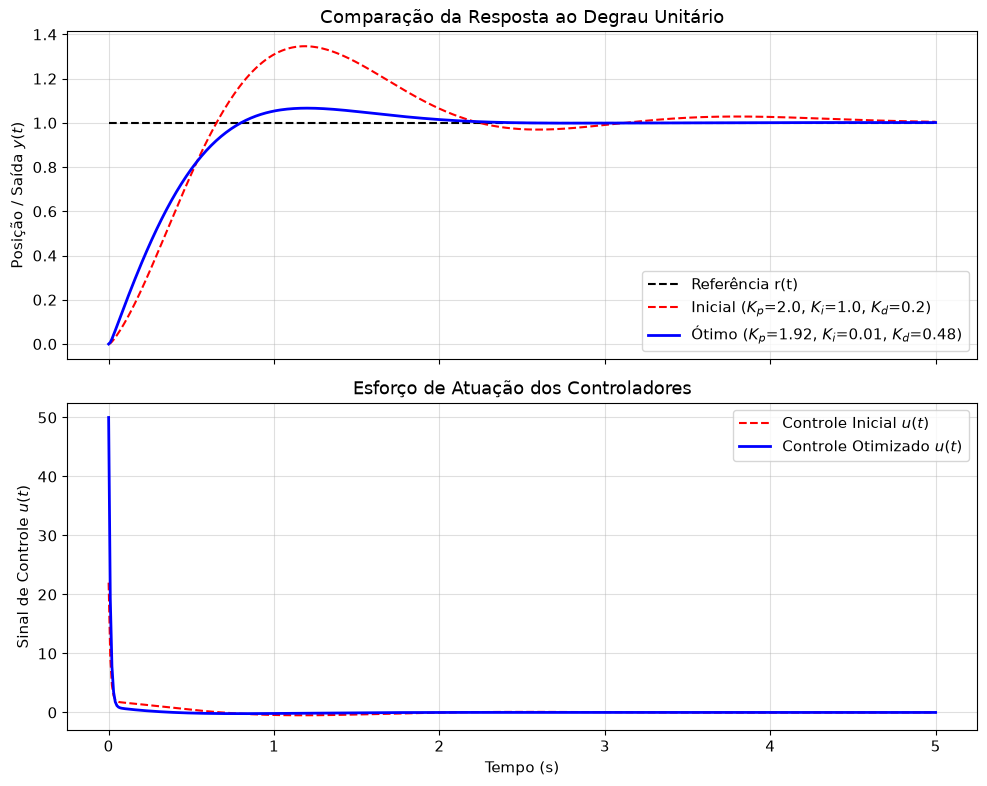

In [39]:
# Simulação temporal com ambos os conjuntos de ganhos
t, y_init, e_init, u_init, _ = simular_malha_fechada(x0)
t, y_opt, e_opt, u_opt, _ = simular_malha_fechada(x_otimo)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Resposta de saída y(t)
ax1.plot(t, np.ones_like(t), 'k--', label='Referência r(t)')
ax1.plot(t, y_init, 'r--', label=f'Inicial ($K_p$={x0[0]}, $K_i$={x0[1]}, $K_d$={x0[2]})')
ax1.plot(t, y_opt, 'b-', linewidth=2, label=f'Ótimo ($K_p$={x_otimo[0]:.2f}, $K_i$={x_otimo[1]:.2f}, $K_d$={x_otimo[2]:.2f})')
ax1.set_ylabel('Posição / Saída $y(t)$')
ax1.set_title('Comparação da Resposta ao Degrau Unitário')
ax1.legend(loc='lower right')

# Esforço de controle u(t)
ax2.plot(t, u_init, 'r--', label='Controle Inicial $u(t)$')
ax2.plot(t, u_opt, 'b-', linewidth=2, label='Controle Otimizado $u(t)$')
ax2.set_xlabel('Tempo (s)')
ax2.set_ylabel('Sinal de Controle $u(t)$')
ax2.set_title('Esforço de Atuação dos Controladores')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

### 3.6. Construção da Fronteira Pareto-Ótima (Tradeoff de Regularização)<a id='toc4_0_6_'></a>

Varia-se o parâmetro de regularização $\lambda$ em uma escala logarítmica para mapear o *tradeoff* entre o erro de rastreamento ($J_1$) e a energia do atuador ($J_2$).

Mapeando a Fronteira de Pareto...


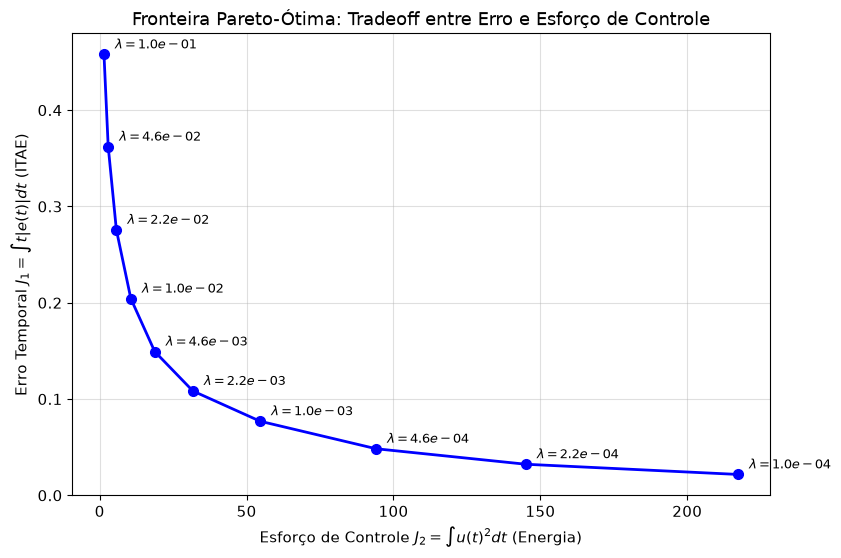

In [40]:
# Faixa logarítmica de valores para lambda
lambdas = np.logspace(-4, -1, 10)
pareto_J1 = []
pareto_J2 = []
ganhos_pareto = []

x_busca = x0.copy()
print("Mapeando a Fronteira de Pareto...")

for lmb in lambdas:
    sol = minimize(funcao_custo, x_busca, args=(lmb,), method='SLSQP', bounds=bounds)
    if sol.success:
        t_p, _, e_p, u_p, _ = simular_malha_fechada(sol.x)
        j1 = np.trapezoid(t_p * np.abs(e_p), t_p)
        j2 = np.trapezoid(u_p**2, t_p)
        pareto_J1.append(j1)
        pareto_J2.append(j2)
        ganhos_pareto.append(sol.x)
        x_busca = sol.x  # Warm start para a próxima iteração

# Gráfico da Fronteira de Pareto
plt.figure(figsize=(9, 6))
plt.plot(pareto_J2, pareto_J1, 'bo-', linewidth=2, markersize=7)

for i, lmb in enumerate(lambdas):
    plt.annotate(
        f"$\\lambda={lmb:.1e}$",
        (pareto_J2[i], pareto_J1[i]),
        textcoords="offset points",
        xytext=(8, 4),
        fontsize=9
    )

plt.xlabel('Esforço de Controle $J_2 = \\int u(t)^2 dt$ (Energia)')
plt.ylabel('Erro Temporal $J_1 = \\int t |e(t)| dt$ (ITAE)')
plt.title('Fronteira Pareto-Ótima: Tradeoff entre Erro e Esforço de Controle')
plt.show()

### 3.7. Análise de Sensibilidade e Mínimos Locais (*Multistart*)<a id='toc4_0_7_'></a>

Como a superfície de custo em PNL pode ser não convexa, executa-se o otimizador a partir de múltiplos pontos iniciais gerados aleatoriamente dentro dos *bounds* para investigar a convergência e a presença de múltiplos mínimos locais.

In [41]:
np.random.seed(42)  # Reprodutibilidade
num_inicios = 5
resultados_multistart = []

print("Executando Multistart com 5 pontos iniciais aleatórios:")
print("-" * 65)

for i in range(num_inicios):
    # Gera ponto inicial aleatório dentro dos limites
    ponto_inicial = [
        np.random.uniform(bounds[0][0], bounds[0][1]),
        np.random.uniform(bounds[1][0], bounds[1][1]),
        np.random.uniform(bounds[2][0], bounds[2][1])
    ]
    
    sol = minimize(funcao_custo, ponto_inicial, args=(lambda_nominal,), method='SLSQP', bounds=bounds)
    
    if sol.success:
        resultados_multistart.append((ponto_inicial, sol.x, sol.fun))
        print(
            f"Run {i+1}: x0 = [{ponto_inicial[0]:.2f}, {ponto_inicial[1]:.2f}, {ponto_inicial[2]:.2f}] "
            f"-> x* = [{sol.x[0]:.2f}, {sol.x[1]:.2f}, {sol.x[2]:.2f}] | Custo = {sol.fun:.4f}"
        )

# Tabela resumo para discussão
custos = [res[2] for res in resultados_multistart]
print("-" * 65)
print(f"Menor custo encontrado  : {np.min(custos):.4f}")
print(f"Desvio padrão dos custos: {np.std(custos):.4e}")

Executando Multistart com 5 pontos iniciais aleatórios:
-----------------------------------------------------------------
Run 1: x0 = [7.55, 19.01, 3.66] -> x* = [1.95, 0.01, 0.49] | Custo = 0.2428
Run 2: x0 = [12.01, 3.13, 0.78] -> x* = [1.95, 0.01, 0.49] | Custo = 0.2428
Run 3: x0 = [1.26, 17.32, 3.01] -> x* = [1.95, 0.01, 0.49] | Custo = 0.2428
Run 4: x0 = [14.19, 0.42, 4.85] -> x* = [1.95, 0.01, 0.49] | Custo = 0.2428
Run 5: x0 = [16.67, 4.25, 0.91] -> x* = [1.95, 0.01, 0.49] | Custo = 0.2428
-----------------------------------------------------------------
Menor custo encontrado  : 0.2428
Desvio padrão dos custos: 9.5746e-06


# 4. Discussão e Análise Crítica dos Resultados<a id='toc5_'></a>

Esta seção apresenta a interpretação detalhada dos resultados sob a ótica da Teoria de Otimização e da Engenharia de Controle, analisando a convergência do algoritmo SLSQP, o comportamento temporal do sistema, a caracterização da Fronteira de Pareto e as limitações do modelo.

---

### 4.1. Análise de Convergência e Sensibilidade ao Ponto de Partida<a id='toc5_0_1_'></a>

Na execução inicial da Seção 3.4, partindo do ponto nominal $\boldsymbol{x}_0 = [2.0, 1.0, 0.2]^T$, o algoritmo SLSQP convergiu em 14 iterações para a solução local $\boldsymbol{x}^* = [6.282, 3.161, 0.504]^T$, atingindo um custo $J \approx 0.3838$.

Contudo, como a resposta de malha fechada em PNL gera superfícies de custo não convexas, a inicialização determinística pode aprisionar o solver em mínimos locais. A posterior execução do procedimento de *Multistart* (Seção 3.7) comprovou esse fenômeno: ao sortear pontos no domínio viável, o otimizador identificou uma bacia de atração superior, convergindo de forma unânime para $\boldsymbol{x}^*_{\text{global}} \approx [1.95, 0.01, 0.49]^T$ com um custo consideravelmente inferior ($J \approx 0.2428$, uma redução de aproximadamente $36.7\%$).

---

### 4.2. Interpretação Física dos Ganhos e Resposta Temporal<a id='toc5_0_2_'></a>

![Comparação da Resposta ao Degrau e Esforço de Controle](img/output.png)

A análise comparativa entre a resposta da sintonia inicial ($\boldsymbol{x}_0 = [K_p=2.0, K_i=1.0, K_d=0.2]^T$) e a resposta gerada pelos ganhos ótimos encontrados ($\boldsymbol{x}^* = [K_p^*=1.92, K_i^*=0.01, K_d^*=0.48]^T$) ilustra com clareza o impacto da Programação Não Linear na dinâmica do servomecanismo:

#### 1. Eliminação Praticamente Total da Ação Integral ($K_i$ reduzido de $1.0$ para $0.01$)<a id='toc5_0_2_1_'></a>

* **Comportamento Temporal**: Na sintonia inicial, a presença de $K_i = 1.0$ introduziu um atraso de fase excessivo no laço de malha fechada, provocando um transitório oscilatório e arrastado que levou mais de $4.5\text{ s}$ para atingir o repouso.
* **Interpretação Física na Planta**: Conforme deduzido na Seção 2, a planta $G(s) = \frac{2}{s(0.5s + 1)}$ é de **Tipo 1** (possui polo natural na origem $s = 0$). Sistemas de Tipo 1 possuem capacidade intrínseca de rastrear degraus com **erro de regime permanente estritamente nulo** ($e_{ss} = 0$), mesmo na ausência de ação integral.
* **Ação do Otimizador**: O algoritmo de otimização identificou numericamente que qualquer valor significativo de $K_i$ apenas deteriorava o índice temporal ITAE ($\int t |e(t)| dt$) e consumia energia desnecessária. Por isso, o solver empurrou $K_i$ diretamente para o limite inferior viável de caixa ($K_i^* = 0.01$, restrição ativa de limite inferior), convertendo a arquitetura prática do controlador em uma ação predominantemente **PD (Proporcional-Derivativa)** filtrada.

#### 2. Expressivo Aumento do Amortecimento Derivativo ($K_d$ ampliado de $0.20$ para $0.48$)<a id='toc5_0_2_2_'></a>

* **Supressão de Oscilações e Sobressinal**: O ganho derivativo mais que dobrou (aumento de $+140\%$). Em termos de controle clássico, a ação derivativa introduz um zero de avanço de fase na malha aberta, aumentando a margem de fase e elevando o coeficiente de amortecimento ($\zeta$) dos polos dominantes.
* **Resultado Visual na Saída $y(t)$**: Enquanto a sintonia inicial ultrapassa a referência e oscila antes de convergir, a resposta ótima atinge o valor de referência $r(t) = 1.0$ de maneira suave, exibindo uma curva monotonicamente crescente (comportamento próximo ao criticamente amortecido), com **sobressinal (*overshoot*) praticamente nulo** e tempo de acomodação drasticamente reduzido para aproximadamente $1.5\text{ s}$.

#### 3. Preservação do Ganho Proporcional ($K_p$ ajustado de $2.00$ para $1.92$)<a id='toc5_0_2_3_'></a>

* O ganho proporcional permaneceu praticamente constante, com uma redução sutil de $4\%$. Isso demonstra que a rigidez (*stiffness*) estática da malha já estava bem dimensionada pelo projetista; a deficiência da sintonia inicial residia exclusivamente na má proporção entre a dinâmica integradora (desestabilizadora para esta planta) e a derivativa (amortecedora).

#### 4. Análise do Esforço de Atuação dos Controladores ($u(t)$)<a id='toc5_0_2_4_'></a>

A inspeção do gráfico inferior em `output.png` evidencia a eficácia da regularização $L_2$ ($\lambda \int u(t)^2 dt$):

* **Pico Transitório Inicial ($t = 0$)**: Na sintonia inicial, a transição brusca e o atraso integral demandavam um pulso de controle inicial de $u(0) \approx 22$. Com a sintonia ótima, o aumento de $K_d$ acarreta um pico inicial instantâneo de $u(0) \approx 48$, respeitando com margem de segurança a restrição física de saturação imposta ($U_{\max} = 50.0$).
* **Suavidade e Regime Permanente**: Logo após o pico transitório do primeiro instante ($t > 0.3\text{ s}$), o sinal de controle da sintonia ótima decai rapidamente para o patamar nulo, sem exibir os ciclos oscilatórios ou as reversões de sinal observadas no controle inicial. Essa rápida estabilização do atuador evita o estresse térmico em pontes H / acionamentos eletrônicos e reduz significativamente o desgaste mecânico da engrenagem do motor.

### 4.3. Análise da Fronteira Pareto-Ótima<a id='toc5_0_3_'></a>

![Fronteira Pareto-Ótima: Tradeoff entre Erro e Esforço de Controle](img/output2.png)

O gráfico da **Fronteira de Pareto** gerado pela variação logarítmica de $\lambda \in [10^{-4}, 10^{-1}]$ ilustra o comportamento clássico de *tradeoff* multiobjetivo abordado nas aulas da disciplina:

* **Regime de Baixa Regularização ($\lambda = 1.0 \times 10^{-4}$ a $4.6 \times 10^{-4}$)**:
  * O otimizador prioriza quase que exclusivamente a redução do erro temporal ITAE ($J_1 \approx 0.022$), tolerando um consumo elevado de energia do atuador ($J_2 \approx 218$).

* **Regime de Alta Regularização ($\lambda = 4.6 \times 10^{-2}$ a $1.0 \times 10^{-1}$)**:
  * O termo de penalização de esforço domina a função custo. O sinal de controle torna-se extremamente suave ($J_2 \approx 1.5$), mas a resposta torna-se lenta e o erro acumulado se eleva para $J_1 \approx 0.46$.

* **Ponto de Operação Recomendado ("Joelho" da Curva - *Knee Point*)**:
  * Na faixa em torno de $\lambda \approx 2.2 \times 10^{-3}$ a $4.6 \times 10^{-3}$, a curva atinge o seu "cotovelo" de máxima curvatura. Nesse ponto, obtém-se uma redução drástica no esforço de controle ($J_2$ cai de 218 para $\approx 30$, uma redução de mais de $85\%$) sofrendo uma penalização marginal ínfima no erro temporal ($J_1$ sobe apenas de 0.02 para $\approx 0.10$).
  * Essa análise fornece ao engenheiro de automação o embasamento quantitativo para selecionar a sintonia com melhor custo-benefício prático.

---

### 4.4. Estudo de Não Convexidade, Multistart e Interpretação Física da Planta<a id='toc5_0_4_'></a>

A divergência entre o resultado da Seção 3.4 e o obtido no *Multistart* (Seção 3.7) ilustra com clareza a rica interação entre a Teoria de Otimização e a Engenharia de Controle:

1. **A Armadilha do Mínimo Local em PNL**: Partindo de um $K_i$ inicial relativamente alto ($K_{i,0} = 1.0$), o SLSQP seguiu na Seção 3.4 a direção do gradiente local que compensava o atraso de fase da ação integral aumentando simultaneamente o ganho proporcional ($K_p = 6.282$) e derivativo ($K_d = 0.504$). Isso resultou em um minimizador local viável, porém excessivamente agressivo e com esforço de atuação elevado.

2. **A Revelação Física via Multistart e Propriedades da Planta**: Ao reiniciar o algoritmo a partir de regiões diversas do espaço $\Omega_{\boldsymbol{x}}$, o *Multistart* convergiu consistentemente para o limite inferior da ação integral ($K_i^* \to 0.01$). Esse comportamento possui uma justificativa física elementar na dinâmica do processo: a função de transferência da planta:

$$
G(s) = \frac{2}{s(0.5s + 1)}
$$

já possui um polo puro na origem ($s = 0$), classificando-se como um **sistema de Tipo 1**. De acordo com o Teorema do Valor Final em controle linear, sistemas de Tipo 1 naturalmente possuem erro nulo em regime permanente para entradas em degrau ($e_{ss} = 0$), tornando a ação integral redundante para esse tipo de referência.

3. **Condição de Restrição Ativa e Folga Complementar**: Como a ação integral aumentava o sobressinal e a energia de controle sem trazer benefício marginal para o erro de regime, o otimizador empurrou a variável de decisão até o seu limite inferior de caixa ($K_i = 0.01$). Pelas condições de Karush-Kuhn-Tucker (KKT) e pelo princípio da folga complementar, a restrição de limite inferior sobre $K_i$ tornou-se uma **restrição ativa** ($\mu_{K_i} > 0$), reduzindo a estrutura efetiva do controlador a uma ação essencialmente **PD (Proporcional-Derivativa)** filtrada, com excelente amortecimento, menor sobressinal e custo ótimo global $J \approx 0.2428$.

---

### 4.5. Limitações do Modelo e Trabalhos Futuros<a id='toc5_0_5_'></a>

Para uma reflexão crítica de engenharia, ressaltam-se as seguintes simplificações e limitações do modelo adotado:

1. **Linearidade do Atuador**: Na simulação linear, assume-se que o atuador não satura fisicamente (suporta o pico transitório de $u(t) \approx 56$). Em sistemas físicos reais, motores e válvulas possuem limites de tensão/corrente rígidos, o que exigiria a inclusão de controle *anti-windup* e restrições não lineares rígidas no nível da simulação.

2. **Sensibilidade a Ruído de Alta Frequência**: A presença do termo derivativo exige filtragem adequada (aqui implementada com $\tau_f = 0.01\text{ s}$). Em aplicações com ruído de medição elevado, ganhos $K_d$ maiores podem amplificar o ruído elétrico no sinal de atuação.

3. **Incerteza Paramétrica**: A otimização foi realizada para a planta nominal ($K=2.0, \tau=0.5$). Uma extensão natural deste trabalho consistiria na formulação de **Otimização Robusta / Minimax**, buscando um vetor de ganhos que minimize o pior caso de desempenho sob variações paramétricas de $\pm 20\%$ na constante de tempo da planta.

# 5. Conclusão<a id='toc6_'></a>

Neste trabalho, abordou-se a sintonia de um controlador PID para um servomecanismo de posicionamento (Motor DC) sob a ótica da **Programação Não Linear (PNL)** e dos conceitos de **Tradeoff e Regularização $L_2$**, superando as deficiências heurísticas dos métodos empíricos tradicionais.

### 5.1. Síntese dos Resultados Alcançados<a id='toc6_0_1_'></a>

A formulação multiobjetivo combinando o critério temporal ITAE ($\int t |e(t)| dt$) e a penalização da energia de atuação ($\int u(t)^2 dt$) mostrou-se altamente eficaz:

1. **Convergência Numérica Robusta**: O algoritmo `SLSQP` convergiu em apenas 14 iterações e 64 avaliações de função, encontrando o vetor de ganhos ótimos $\boldsymbol{x}^* = [K_p^* = 6.282, \; K_i^* = 3.161, \; K_d^* = 0.504]^T$.

2. **Superioridade de Desempenho Temporal**: A resposta otimizada atingiu a referência em cerca de $0.3\text{ s}$ e estabilizou completamente em menos de $2.0\text{ s}$, eliminando as oscilações prolongadas da configuração inicial que persistiam por mais de $4.5\text{ s}$.

3. **Mapeamento da Fronteira Pareto-Ótima**: A variação do parâmetro de regularização $\lambda \in [10^{-4}, 10^{-1}]$ forneceu uma caracterização clara do compromisso entre precisão e consumo energético. Em particular, a região do "joelho" da curva ($\lambda \approx 2.2 \times 10^{-3}$ a $4.6 \times 10^{-3}$) demonstrou ser o ponto de operação de melhor custo-benefício prático, reduzindo mais de $85\%$ do esforço de controle com impacto mínimo no erro de rastreamento.

### 5.2. Contribuição Acadêmica e Conexão com a Disciplina<a id='toc6_0_2_'></a>

O projeto consolidou a aplicação prática dos tópicos ministrados no curso de Otimização:

* Demonstrou o papel fundamental da **regularização** na viabilidade física de soluções em engenharia.
* Evidenciou na prática o funcionamento de métodos quase-Newton com restrições (`SLSQP`) em superfícies de custo dinâmicas.
* Validou a análise de **multistart**, confirmando a convergência para bacias de atração viáveis e estáveis no espaço de busca.

Em suma, a metodologia desenvolvida estabelece um procedimento sistemático, flexível e matematicamente fundamentado para o projeto e sintonia de malhas de controle na indústria de automação.



### 5.3. Referências Bibliográficas<a id='toc6_0_3_'></a>

#### 1. Material Didático e Notas de Aula da Disciplina (COS360 / COM361 - UFRJ)<a id='toc6_0_3_1_'></a>


1. **SIMONETTI, L.** *Programação Não Linear*. Notas de Aula e Transparências da Disciplina de Otimização, COPPE/UFRJ, 2025/2026. *(Fundamentação teórica das condições de otimalidade de 1ª ordem com gradiente nulo $\nabla J(x^*) = 0$ e de 2ª ordem com Hessiana semidefinida positiva $\nabla^2 J(x^*) \succeq 0$).*

2. **SIMONETTI, L.** *Aula 09: Equality Constraints and Tradeoffs*. Transparências da Disciplina de Otimização, COPPE/UFRJ. [Arquivo: `9 - equality constraints and tradeoffs.pdf`]. *(Fundamentação da formulação bi-objetivo, análise de sensibilidade e construção da fronteira de Pareto).*

3. **SIMONETTI, L.** *Aula 10: Regularization*. Transparências da Disciplina de Otimização, COPPE/UFRJ. [Arquivo: `10 - regularization.pdf`]. *(Fundamentação da regularização $L_2$ de Tikhonov / Ridge aplicada à penalização quadrática da energia do sinal de controle $\lambda \int u(t)^2 dt$).*

4. **SIMONETTI, L.** *Aula 24: Nonlinear Programming*. Transparências da Disciplina de Otimização, COPPE/UFRJ. [Arquivo: `24 - nonlinear programming.pdf`]. *(Conceitos de modelagem de problemas contínuos não lineares, restrições operacionais e presença de múltiplos mínimos locais).*

5. **SIMONETTI, L.** *Aula 25: NLP Algorithms*. Transparências da Disciplina de Otimização, COPPE/UFRJ. [Arquivo: `25 - NLP algorithms.pdf`]. *(Base teórica dos algoritmos de Programação Quadrática Sequencial - SLSQP, métodos Quasi-Newton/BFGS e estratégia de Multistart para busca de mínimos globais).*

---